## Sprint 3 — EDA: OULAD (Open University Learning Analytics Dataset)

Per the implementation plan, this notebook covers:
- Click distribution
- Weekly engagement
- Assessment scores
- Withdrawal / fail distribution (`final_result`)
- Engagement vs. outcome

**Reminder from the plan (Section 1.3):** OULAD and UCI are never joined —
they're different, unrelated student populations. This notebook only looks at OULAD
on its own.

**Scale note:** `studentVle.csv` is ~10.65M rows (~433 MB). We use chunked reads and
aggregate-on-the-fly rather than loading it fully into memory, per the plan's
description of it as "the source for weekly engagement sequences" — meaning we work
with it, not blow up the kernel on it.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 100



In [2]:
PROJECT_ROOT = r"C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli"

RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw", "oulad_data")

def read_oulad(name, **kwargs):
    return pd.read_csv(os.path.join(RAW_DIR, name), na_values="?", skipinitialspace=True, **kwargs)

## 1. Load the small/medium tables

`studentInfo`, `studentRegistration`, `courses`, `Virtual Learning Environment` `(vle)` , `assessments`,
`studentAssessment` are all small enough to load in full. `studentVle` (the ~10.65M-
row interaction log) is handled separately in Section 4.

In [3]:
student_info = read_oulad("studentInfo.csv")
registration = read_oulad("studentRegistration.csv")
courses = read_oulad("courses.csv")
vle = read_oulad("vle.csv")
assessments = read_oulad("assessments.csv")
student_assessment = read_oulad("studentAssessment.csv")

for name, d in [("studentInfo", student_info), ("studentRegistration", registration),
                 ("courses", courses), ("vle", vle), ("assessments", assessments),
                 ("studentAssessment", student_assessment)]:
    print(f"{name:20s} {d.shape[0]:>8,} rows x {d.shape[1]} cols")

studentInfo            32,593 rows x 12 cols
studentRegistration    32,593 rows x 5 cols
courses                    22 rows x 3 cols
vle                     6,364 rows x 6 cols
assessments               206 rows x 6 cols
studentAssessment     173,912 rows x 5 cols


In [4]:
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [5]:
registration.head()

,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0
3,AAA,2013J,31604,-52.0,NaN
4,AAA,2013J,32885,-176.0,NaN


In [6]:
courses.head()

,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240


In [7]:
vle.head()

,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,NaN,NaN
1,546712,AAA,2013J,oucontent,NaN,NaN
2,546998,AAA,2013J,resource,NaN,NaN
3,546888,AAA,2013J,url,NaN,NaN
4,547035,AAA,2013J,resource,NaN,NaN


In [8]:
assessments.head()

,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0


In [9]:
student_assessment.head()

,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0


## 2. Missing values and dtypes (studentInfo)

In [10]:
student_info.info()
print()
# Normalize object columns: strip whitespace and replace literal '?' with NA
for col in student_info.select_dtypes(include=['object']).columns:
    student_info[col] = student_info[col].str.strip()
# Replace any remaining literal '?' values (including ones with surrounding spaces)
student_info.replace('?', pd.NA, inplace=True)

missing = student_info.isna().sum()
missing = missing[missing > 0]
print("Missing values in studentInfo:")
print(missing if len(missing) else "None")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   code_module           32593 non-null  object
 1   code_presentation     32593 non-null  object
 2   id_student            32593 non-null  int64 
 3   gender                32593 non-null  object
 4   region                32593 non-null  object
 5   highest_education     32593 non-null  object
 6   imd_band              31482 non-null  object
 7   age_band              32593 non-null  object
 8   num_of_prev_attempts  32593 non-null  int64 
 9   studied_credits       32593 non-null  int64 
 10  disability            32593 non-null  object
 11  final_result          32593 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.0+ MB

Missing values in studentInfo:
imd_band    1111
dtype: int64


In [11]:
registration.info()
print()
missing = registration.isna().sum()
missing = missing[missing > 0]
print("Missing values in registration:")
print(missing if len(missing) else "None")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   code_module          32593 non-null  object 
 1   code_presentation    32593 non-null  object 
 2   id_student           32593 non-null  int64  
 3   date_registration    32548 non-null  float64
 4   date_unregistration  10072 non-null  float64
dtypes: float64(2), int64(1), object(2)
memory usage: 1.2+ MB

Missing values in registration:
date_registration         45
date_unregistration    22521
dtype: int64


In [12]:
courses.info()
print()
missing = courses.isna().sum()
missing = missing[missing > 0]
print("Missing values in courses:")
print(missing if len(missing) else "None")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   code_module                 22 non-null     object
 1   code_presentation           22 non-null     object
 2   module_presentation_length  22 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 660.0+ bytes

Missing values in courses:
None


In [13]:
vle.info()
print()
missing = vle.isna().sum()
missing = missing[missing > 0]
print("Missing values in vle:")
print(missing if len(missing) else "None")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6364 entries, 0 to 6363
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_site            6364 non-null   int64  
 1   code_module        6364 non-null   object 
 2   code_presentation  6364 non-null   object 
 3   activity_type      6364 non-null   object 
 4   week_from          1121 non-null   float64
 5   week_to            1121 non-null   float64
dtypes: float64(2), int64(1), object(3)
memory usage: 298.4+ KB

Missing values in vle:
week_from    5243
week_to      5243
dtype: int64


In [14]:
assessments.info()
print()
missing = assessments.isna().sum()
missing = missing[missing > 0]
print("Missing values in assessments:")
print(missing if len(missing) else "None")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   code_module        206 non-null    object 
 1   code_presentation  206 non-null    object 
 2   id_assessment      206 non-null    int64  
 3   assessment_type    206 non-null    object 
 4   date               195 non-null    float64
 5   weight             206 non-null    float64
dtypes: float64(2), int64(1), object(3)
memory usage: 9.8+ KB

Missing values in assessments:
date    11
dtype: int64


In [15]:
student_assessment.info()
print()
missing = student_assessment.isna().sum()
missing = missing[missing > 0]
print("Missing values in student_assessment:")
print(missing if len(missing) else "None")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173912 entries, 0 to 173911
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id_assessment   173912 non-null  int64  
 1   id_student      173912 non-null  int64  
 2   date_submitted  173912 non-null  int64  
 3   is_banked       173912 non-null  int64  
 4   score           173739 non-null  float64
dtypes: float64(1), int64(4)
memory usage: 6.6 MB

Missing values in student_assessment:
score    173
dtype: int64


Unlike UCI, OULAD uses `"?"` as an explicit missing marker in the raw files (mapped
to `NaN` on read above). `imd_band` (deprivation index) is the column most likely to
carry real missingness here — worth checking before it's used as a feature, since
missing deprivation data is not necessarily random.

## 3. `final_result` — the withdrawal / fail distribution (target)

final_result
Distinction     3024
Pass           12361
Fail            7052
Withdrawn      10156
Name: count, dtype: int64

Overall at-risk rate: 0.528


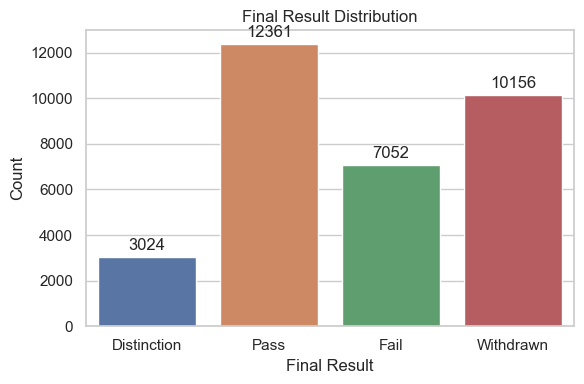

In [16]:
result_order = ["Distinction", "Pass", "Fail", "Withdrawn"]

# Count results
result_counts = student_info["final_result"].value_counts().reindex(result_order, fill_value=0)
print(result_counts)

# At-risk rate
student_info["at_risk"] = student_info["final_result"].isin(["Fail", "Withdrawn"])
print(f"\nOverall at-risk rate: {student_info['at_risk'].mean():.3f}")

# Bar chart
fig, ax = plt.subplots(figsize=(6, 4))

bars = sns.barplot(
    x=result_counts.index,
    y=result_counts.values,
    ax=ax
)

# Add count on top of bars
ax.bar_label(ax.containers[0], padding=3)

ax.set_title("Final Result Distribution")
ax.set_ylabel("Count")
ax.set_xlabel("Final Result")

plt.tight_layout()
plt.show()

# 1. Final Result Distribution

### Analysis

- **Pass** is the largest outcome, with **12,361 students (37.9%)**.
- **Withdrawn** is the second-largest group, with **10,156 students (31.2%)**.
- **Fail** accounts for **7,052 students (21.6%)**.
- **Distinction** is the smallest category, with **3,024 students (9.3%)**.
- Therefore, although passing is the most common outcome, a substantial proportion of students either fail or withdraw.

### Conclusion

The distribution indicates that **academic success is concentrated in the Pass category, but withdrawal is also a major issue**. The relatively small proportion achieving Distinction suggests that high academic achievement is considerably less common than simply passing.

---

In [17]:
mod_result = student_info.groupby(["code_module", "final_result"]).size().unstack(fill_value=0)
mod_result = mod_result.reindex(columns=result_order)
mod_result_pct = mod_result.div(mod_result.sum(axis=1), axis=0) * 100

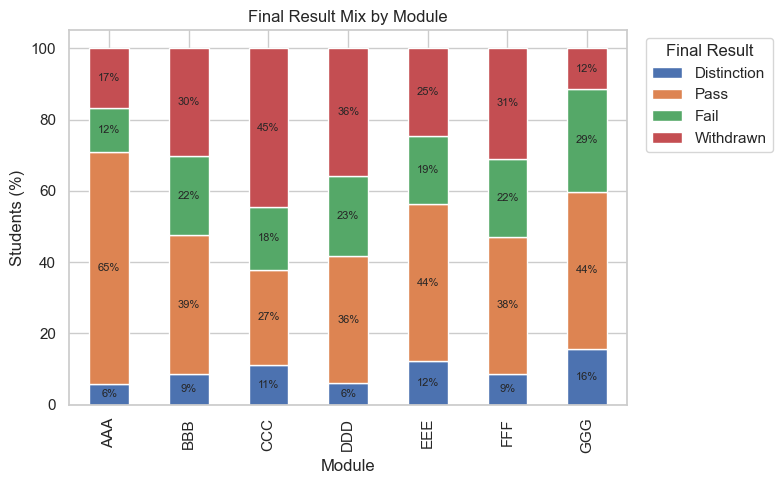

In [18]:
ax = mod_result_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

for container in ax.containers:
    labels = [
        f"{bar.get_height():.0f}%"
        if bar.get_height() >= 5 else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=8)

ax.set_title("Final Result Mix by Module")
ax.set_xlabel("Module")
ax.set_ylabel("Students (%)")
ax.legend(title="Final Result", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

###  Final Result Mix by Module

### Analysis

The outcome distribution varies considerably across modules:

- **AAA:** 65% Pass, 12% Fail, 17% Withdrawn, and 6% Distinction.
- **BBB:** 39% Pass, 22% Fail, 30% Withdrawn, and 9% Distinction.
- **CCC:** 27% Pass, 18% Fail, 45% Withdrawn, and 11% Distinction.
- **DDD:** 36% Pass, 23% Fail, 36% Withdrawn, and 6% Distinction.
- **EEE:** 44% Pass, 19% Fail, 25% Withdrawn, and 12% Distinction.
- **FFF:** 38% Pass, 22% Fail, 31% Withdrawn, and 9% Distinction.
- **GGG:** 44% Pass, 29% Fail, 12% Withdrawn, and 16% Distinction.

CCC has the **highest withdrawal rate**, while GGG has the **highest distinction rate**. AAA has the strongest pass rate.

### Conclusion

Student outcomes differ substantially by module. **AAA appears to have the strongest overall performance**, whereas **CCC presents the greatest retention concern** because of its very high withdrawal rate. GGG stands out for its relatively high Distinction rate but also has the highest Fail rate.

---

## 4. `studentVle` — click distribution (chunked aggregation)

`studentVle.csv` is too large to comfortably explore row-by-row in a notebook, so
we stream it in chunks and build the aggregates we actually need:
- overall `sum_click` distribution (via a running histogram)
- per-student total clicks and days-active (the raw material for weekly engagement
  features)

This mirrors what `data_migration.load_oulad_engagement()` will eventually do when
building `oulad_engagement` in the DB.

In [19]:
vle_path = os.path.join(RAW_DIR, "studentVle.csv")
CHUNK = 1_000_000  # restored -- later deep-dive sections reuse this name for their own chunked reads

per_student_clicks = {}
per_student_days = {}
click_values = []
n_rows = 0

for chunk in pd.read_csv(vle_path, na_values="?", chunksize=CHUNK):
    n_rows += len(chunk)

    # Sample clicks for plotting
    click_values.append(
        chunk["sum_click"].sample(min(20_000, len(chunk)), random_state=0)
    )

    # Total clicks per student
    clicks = chunk.groupby("id_student")["sum_click"].sum()
    for student, clicks_sum in clicks.items():
        per_student_clicks[student] = per_student_clicks.get(student, 0) + clicks_sum

    # Active days per student
    days = chunk.groupby("id_student")["date"].apply(set)
    for student, student_days in days.items():
        per_student_days.setdefault(student, set()).update(student_days)

click_sample = pd.concat(click_values, ignore_index=True)

print(f"Processed {n_rows:,} rows")
print(f"Students: {len(per_student_clicks):,}")

Processed 10,655,280 rows
Students: 26,074


c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


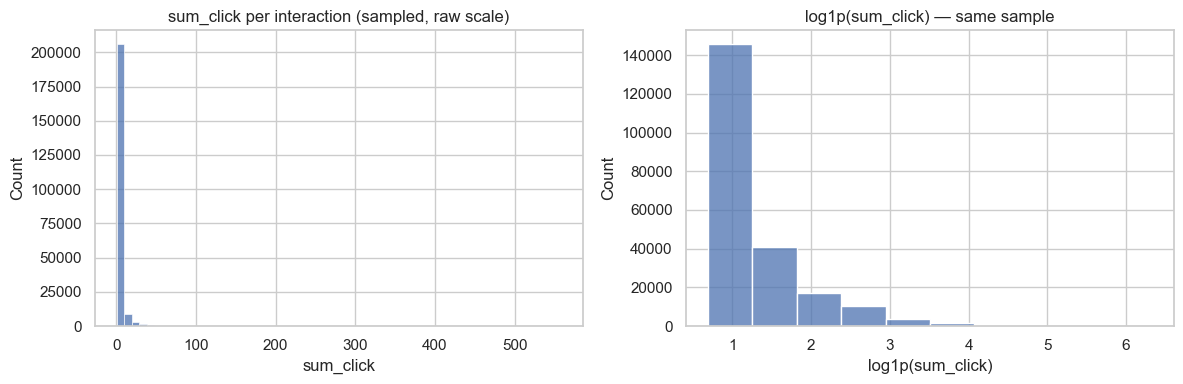

count    220000.00
mean          3.74
std           7.87
min           1.00
25%           1.00
50%           2.00
75%           3.00
max         558.00
Name: sum_click, dtype: float64


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(click_sample, bins=60, ax=axes[0])
axes[0].set_title("sum_click per interaction (sampled, raw scale)")
axes[0].set_xlabel("sum_click")

sns.histplot(np.log1p(click_sample), bins=10, ax=axes[1])
axes[1].set_title("log1p(sum_click) — same sample")
axes[1].set_xlabel("log1p(sum_click)")

plt.tight_layout()
plt.show()

print(click_sample.describe().round(2))

Per-interaction click counts are heavily right-skewed (most interactions are a
handful of clicks; a long tail of high-activity sessions) — a log transform is
worth considering for any model that uses raw click counts as a feature.

## 5. Per-student total engagement vs. outcome

In [21]:
# Create student-level engagement data
engagement = pd.DataFrame({
    "id_student": per_student_clicks.keys(),
    "total_clicks": per_student_clicks.values()
})

engagement["days_active"] = engagement["id_student"].map(
    lambda x: len(per_student_days.get(x, set()))
)

print(f"VLE students: {engagement['id_student'].nunique():,}")

# Get the worst outcome for each student
outcome_rank = {
    "Distinction": 0,
    "Pass": 1,
    "Fail": 2,
    "Withdrawn": 3
}

worst_outcome = (
    student_info
    .assign(rank=student_info["final_result"].map(outcome_rank))
    .sort_values("rank", ascending=False)
    .drop_duplicates("id_student")
    [["id_student", "final_result", "at_risk"]]
)

# Combine engagement with outcome
engagement = engagement.merge(
    worst_outcome,
    on="id_student",
    how="left"
)

print(
    f"Matched outcomes: {engagement['final_result'].notna().sum():,} "
    f"of {len(engagement):,}"
)

engagement.head()

VLE students: 26,074
Matched outcomes: 26,074 of 26,074


,id_student,total_clicks,days_active,final_result,at_risk
0,6516,2791,159,Pass,False
1,11391,934,40,Pass,False
2,23629,161,16,Fail,True
3,23798,590,77,Distinction,False
4,24734,499,56,Pass,False


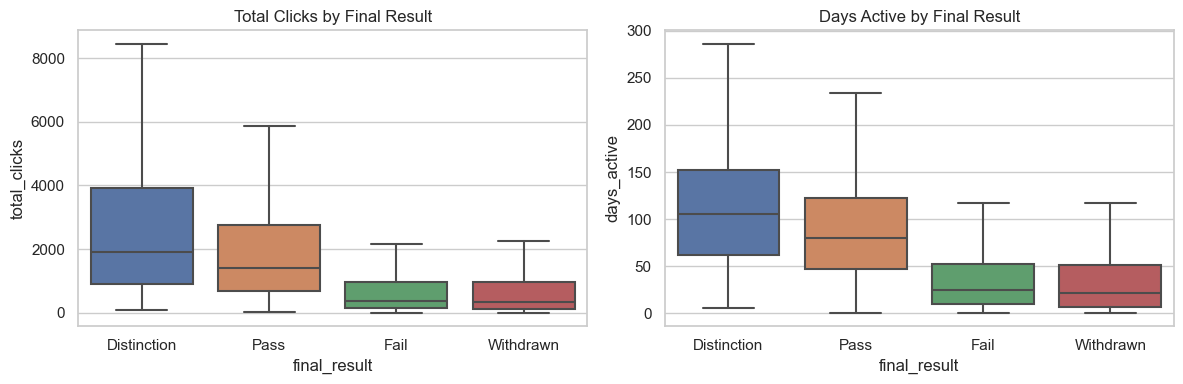

              total_clicks  days_active
final_result                           
Distinction         1914.0        105.0
Pass                1393.0         80.0
Fail                 379.0         25.0
Withdrawn            346.0         22.0


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, column, title in zip(
    axes,
    ["total_clicks", "days_active"],
    ["Total Clicks", "Days Active"]
):
    sns.boxplot(
        data=engagement,
        x="final_result",
        y=column,
        order=result_order,
        showfliers=False,
        ax=ax
    )
    ax.set_title(f"{title} by Final Result")

plt.tight_layout()
plt.show()

# Median values
print(
    engagement.groupby("final_result")[["total_clicks", "days_active"]].median().reindex(result_order)
)

# Total Clicks by Final Result — Boxplot

### Analysis

- **Distinction** students have the highest median total clicks, approximately **1,900**.
- **Pass** students have a lower median, around **1,400**.
- **Fail** and **Withdrawn** students have substantially lower medians, around **300–400**.
- Distinction students also show a very large spread, with values extending above **8,000 clicks**.
- Pass students also have a broad distribution, while Fail and Withdrawn groups are more concentrated at lower engagement levels.

### Conclusion

There is a strong relationship between **student engagement and academic outcome**. Students with higher click activity are much more likely to achieve Distinction or Pass, whereas low engagement is associated with Failure or Withdrawal.

---



### Days Active by Final Result — Boxplot

### Analysis

- Distinction students have the highest median number of active days, approximately **105 days**.
- Pass students have a median around **80 days**.
- Fail and Withdrawn students have much lower medians, approximately **25 and 20 days**, respectively.
- Distinction students also have the widest range, reaching nearly **285 days**.

### Conclusion

Time spent actively participating in the course is strongly associated with better academic outcomes. **Longer and more consistent engagement is characteristic of Distinction and Pass students**, while low activity is associated with Failure and Withdrawal.

---

In [1]:
# At-risk sanity check
ax = sns.barplot(
    data=engagement,
    x="final_result",
    y="at_risk",
    order=result_order,
    errorbar=None
)

ax.set_title("At-Risk by Final Result")
ax.set_ylabel("At-Risk (0 = No, 1 = Yes)")
ax.set_xlabel("Final Result")

plt.tight_layout()
plt.show()

# Correlation
corr_engagement = engagement[
    ["total_clicks", "days_active", "at_risk"]
].corr()

print(corr_engagement.round(2))

NameError: name 'sns' is not defined

## 6. Weekly engagement pattern (module-relative week)

`studentVle.date` is days relative to module start (negative values are pre-start
access). We bucket into module-relative weeks to see the shape of engagement over
the course of a presentation — reading a *sample* of the file this time since we
only need the shape, not per-student totals.

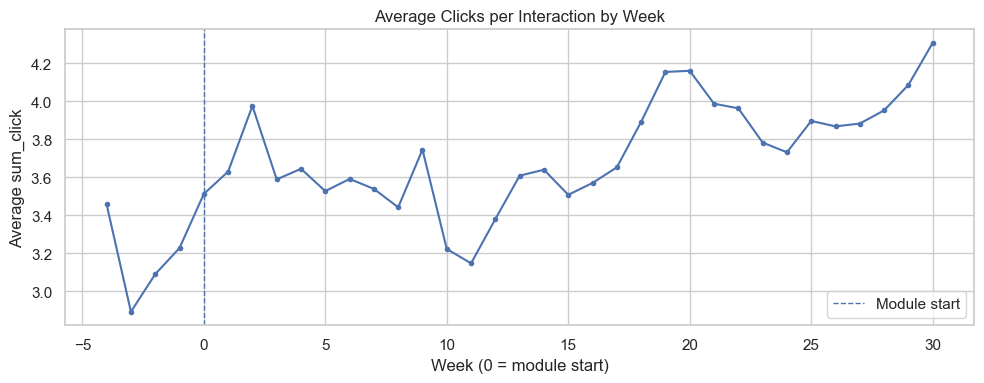

In [24]:
weekly_sum = pd.Series(dtype=float)
weekly_count = pd.Series(dtype=float)

for chunk in pd.read_csv(
    vle_path,
    chunksize=CHUNK,
    usecols=["date", "sum_click"]
):
    chunk["week"] = chunk["date"] // 7

    weekly = chunk.groupby("week")["sum_click"].agg(["sum", "count"])

    weekly_sum = weekly_sum.add(weekly["sum"], fill_value=0)
    weekly_count = weekly_count.add(weekly["count"], fill_value=0)

# Average clicks per interaction
weekly_avg = (weekly_sum / weekly_count).sort_index()
weekly_avg = weekly_avg.loc[-4:30]

# Plot
ax = weekly_avg.plot(figsize=(10, 4), marker="o", markersize=3)

ax.axvline(0, linestyle="--", linewidth=1, label="Module start")
ax.set_title("Average Clicks per Interaction by Week")
ax.set_xlabel("Week (0 = module start)")
ax.set_ylabel("Average sum_click")
ax.legend()

plt.tight_layout()
plt.show()

### Average Clicks per Interaction by Week

### Analysis

- Engagement fluctuates considerably throughout the study period.
- Around the module start (week 0), average clicks are approximately **3.5**.
- Engagement falls slightly around weeks 1–2 before recovering.
- A noticeable increase occurs around weeks **18–20**, when average clicks exceed **4.0**.
- Another strong increase occurs toward the end, reaching approximately **4.3 clicks per interaction at week 30**.
- There are several temporary declines, particularly around weeks 9–11 and 23–24.

### Conclusion

Student engagement is **dynamic rather than constant**. Overall engagement tends to increase toward the later stages of the module, although there are several periods of reduced activity that may represent points where students require additional support.

---

## 7. Assessment scores

In [25]:
student_assessment.info()
print()
print(f"Missing scores: {student_assessment['score'].isna().sum()}")

assessment_full = student_assessment.merge(assessments, on="id_assessment", how="left")
assessment_full.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173912 entries, 0 to 173911
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id_assessment   173912 non-null  int64  
 1   id_student      173912 non-null  int64  
 2   date_submitted  173912 non-null  int64  
 3   is_banked       173912 non-null  int64  
 4   score           173739 non-null  float64
dtypes: float64(1), int64(4)
memory usage: 6.6 MB

Missing scores: 173


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


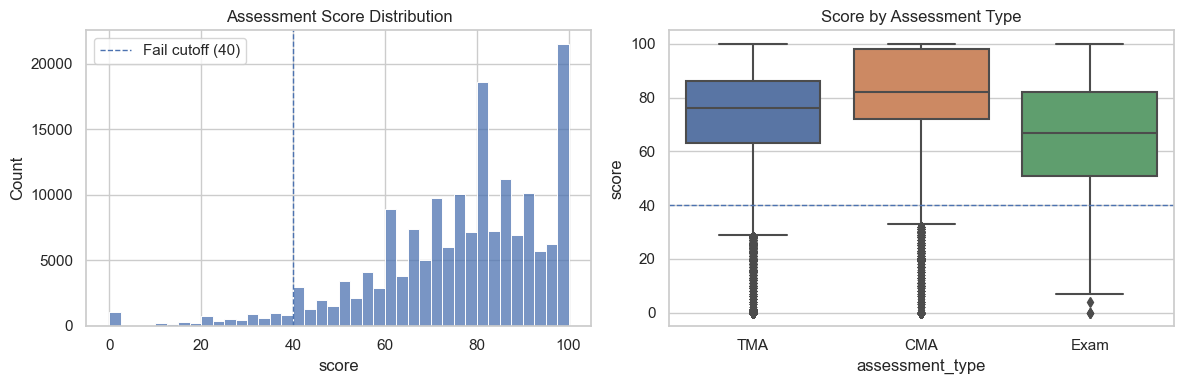

Score Summary:
                   count   mean    std  min   25%   50%   75%    max
assessment_type                                                     
CMA              70527.0  81.03  17.84  0.0  72.0  82.0  98.0  100.0
Exam              4959.0  65.57  20.58  0.0  51.0  67.0  82.0  100.0
TMA              98253.0  72.56  18.43  0.0  63.0  76.0  86.0  100.0


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Score distribution
sns.histplot(student_assessment["score"].dropna(), bins=40, ax=axes[0])
axes[0].axvline(40, linestyle="--", linewidth=1, label="Fail cutoff (40)")
axes[0].set_title("Assessment Score Distribution")
axes[0].legend()

# Score by assessment type
sns.boxplot(
    data=assessment_full,
    x="assessment_type",
    y="score",
    ax=axes[1]
)
axes[1].axhline(40, linestyle="--", linewidth=1)
axes[1].set_title("Score by Assessment Type")

plt.tight_layout()
plt.show()

# Summary statistics
print("Score Summary:")
print(
    assessment_full
    .groupby("assessment_type")["score"]
    .describe()
    .round(2)
)

# 8. Assessment Score Distribution

### Analysis

- Scores are concentrated heavily between approximately **60 and 100**.
- There are particularly large concentrations around scores of **80, 90, and 100**.
- A smaller number of students obtain scores below the **40-point fail cutoff**.
- There is also a noticeable concentration at exactly 100, suggesting that many students achieve maximum marks.

### Conclusion

Overall assessment performance is relatively strong, with most students scoring above the fail threshold. However, the presence of a lower-scoring group indicates that **some students remain academically vulnerable**.

---

In [27]:
below_40 = (student_assessment["score"] < 40).mean()
print(f"Share of individual assessment scores below the 40 fail cutoff: {below_40:.1%}")

# Late submissions relative to due date
late = assessment_full["date_submitted"] > assessment_full["date"]
print(f"Share of assessments submitted after the due date: {late.mean():.1%}")

Share of individual assessment scores below the 40 fail cutoff: 4.4%
Share of assessments submitted after the due date: 28.4%


Score distributions skew high (most submitted assessments pass), which makes sense
— `studentAssessment` only records assessments a student actually *submitted*.
Withdrawn/failing students are more likely to be under-represented here simply by
not submitting, so assessment scores alone will understate risk; they need to be
combined with submission/completion signals (and VLE engagement) rather than used
in isolation.

## 8. Registration timing (context for lead-time analysis, Week 2)

Withdrawal rate: 30.9%


c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


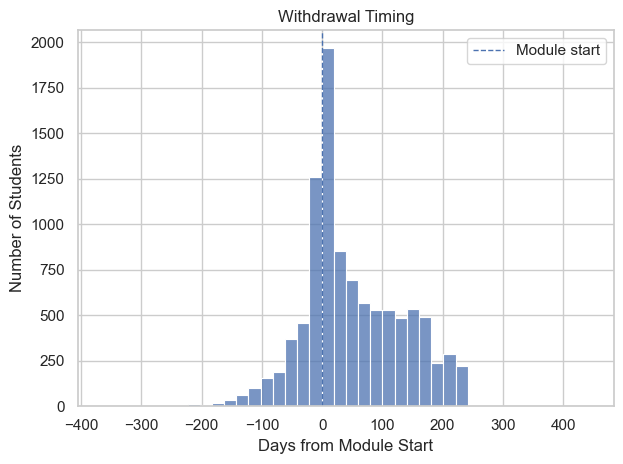

In [28]:
# Identify withdrawals
registration["withdrawn"] = registration["date_unregistration"].notna()

print(f"Withdrawal rate: {registration['withdrawn'].mean():.1%}")

# Plot withdrawal timing
sns.histplot(
    registration.loc[registration["withdrawn"], "date_unregistration"],
    bins=40
)

plt.axvline(0, linestyle="--", linewidth=1, label="Module start")
plt.title("Withdrawal Timing")
plt.xlabel("Days from Module Start")
plt.ylabel("Number of Students")
plt.legend()
plt.tight_layout()
plt.show()

Most withdrawals happen well after the module start rather than immediately —
there's real lead time between "still enrolled" and "withdrawn," which is exactly
what the plan's Week 2 lead-time analysis is designed to exploit (predicting risk
*before* the withdrawal date, not just detecting it after the fact).

## Deep-dive EDA — missingness, distributions, trajectories, and a few quick models

Everything above (Sections 1-8) covers the core plan checklist: load, missing
values, target distribution, click distribution, engagement vs. outcome,
weekly pattern, assessment scores, registration timing. This section goes
deeper on each of those, matching the depth added to `uci_eda.ipynb`:

1. Missingness heatmap + per-column missing counts
2. Type + cardinality summary
3. Value distribution by outcome (violin/box: clicks, days active, scores)
4. Weekly engagement with confidence interval, split by `final_result`
5. Cumulative engagement trajectories (percentile bands, by outcome)
6. Module-level risk map (heatmap)
7. Assessment submission funnel (submitted → pass/fail → withdrawn)
8. Correlation heatmap + quick tree-based feature importance
9. PCA projection colored by `at_risk`
10. Kaplan-Meier survival curve for time-to-withdrawal
11. Missingness co-occurrence clustermap
12. Interactive Plotly chart (module-filterable weekly engagement)
13. Engagement sequence heatmap (week × student, sampled)

### 1. Missingness — heatmap + per-column counts

The `missing = ... isna().sum()` printout in Section 2 already lists *which*
columns have gaps. This adds the visual version: a row-by-row pattern (are
missing values scattered randomly, or do they cluster in certain rows?) and a
sorted bar chart to prioritize which columns are worth an imputation decision
first.

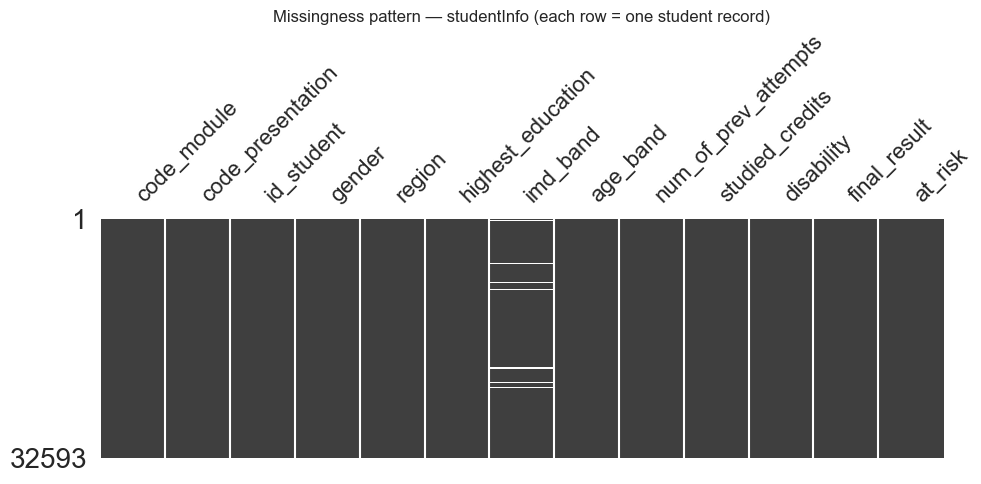

In [29]:
import missingno as msno 
fig, ax = plt.subplots(figsize=(10, 5)) 
msno.matrix(student_info, ax=ax, sparkline=False) 
ax.set_title("Missingness pattern — studentInfo (each row = one student record)") 
plt.tight_layout() 
plt.show()

### Missingness Pattern — `studentInfo`

### Analysis

- Almost all variables have complete data.
- Missingness is visually concentrated in **`imd_band`**.
- The other variables, including gender, region, education, age band, previous attempts, studied credits, final result, and at-risk status, appear essentially complete.

### Conclusion

The dataset has a **very limited missing-data problem**, primarily affecting `imd_band`. This is favorable for analysis because most important variables can be used without extensive imputation.

---

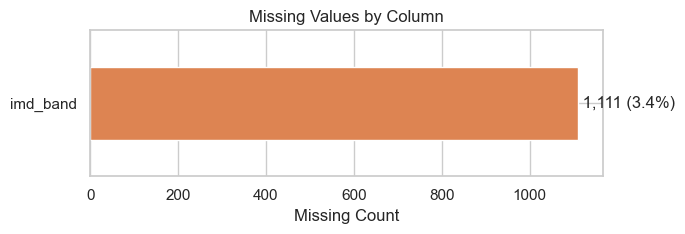

In [30]:
missing = student_info.isna().sum()
missing = missing[missing > 0].sort_values()

ax = missing.plot(
    kind="barh",
    color="#DD8452",
    figsize=(7, max(2.5, 0.4 * len(missing)))
)

ax.set_title("Missing Values by Column")
ax.set_xlabel("Missing Count")

for i, count in enumerate(missing):
    ax.text(
        count,
        i,
        f" {count:,} ({count / len(student_info):.1%})",
        va="center"
    )

plt.tight_layout()
plt.show()

### Missing Values by Column

### Analysis

- Only **`imd_band`** contains substantial missing data.
- There are **1,111 missing values**, representing approximately **3.4%** of the records.
- No other column shown has a comparable missingness problem.

### Conclusion

Missing data is **not a major issue for the dataset**. The relatively small amount of missing `imd_band` information can be handled through appropriate imputation or by treating missingness as a separate category, depending on the modeling approach.

---

### 2. Type + cardinality summary

A single table answering "what kind of column is this" for every column in
`studentInfo` — dtype, number of unique values, and whether that makes it a
good candidate for one-hot encoding (low cardinality) vs. something that needs
different handling (high cardinality, or already numeric).

In [31]:
cardinality_summary = pd.DataFrame({
    "dtype": student_info.dtypes.astype(str),
    "n_unique": student_info.nunique(),
    "n_missing": student_info.isna().sum(),
    "pct_missing": (student_info.isna().mean() * 100).round(1),
}).sort_values("n_unique")

cardinality_summary["likely_role"] = np.where(
    cardinality_summary["dtype"] == "object",
    np.where(cardinality_summary["n_unique"] <= 15, "categorical (low-cardinality)", "categorical (high-cardinality)"),
    "numeric",
)
cardinality_summary

,dtype,n_unique,n_missing,pct_missing,likely_role
gender,object,2,0,0.0,categorical (low-cardinality)
disability,object,2,0,0.0,categorical (low-cardinality)
at_risk,bool,2,0,0.0,numeric
age_band,object,3,0,0.0,categorical (low-cardinality)
code_presentation,object,4,0,0.0,categorical (low-cardinality)
final_result,object,4,0,0.0,categorical (low-cardinality)
highest_education,object,5,0,0.0,categorical (low-cardinality)
code_module,object,7,0,0.0,categorical (low-cardinality)
num_of_prev_attempts,int64,7,0,0.0,numeric
imd_band,object,10,1111,3.4,categorical (low-cardinality)


### 3. Value distribution by outcome — violin/box plots

Section 5 already showed `total_clicks`/`days_active` boxplots by
`final_result`. Violin plots add the *shape* (bimodal? long tail?) on top of
the quartiles, and this adds `score` (from `studentAssessment`) to the same
kind of by-outcome comparison — not shown anywhere yet.

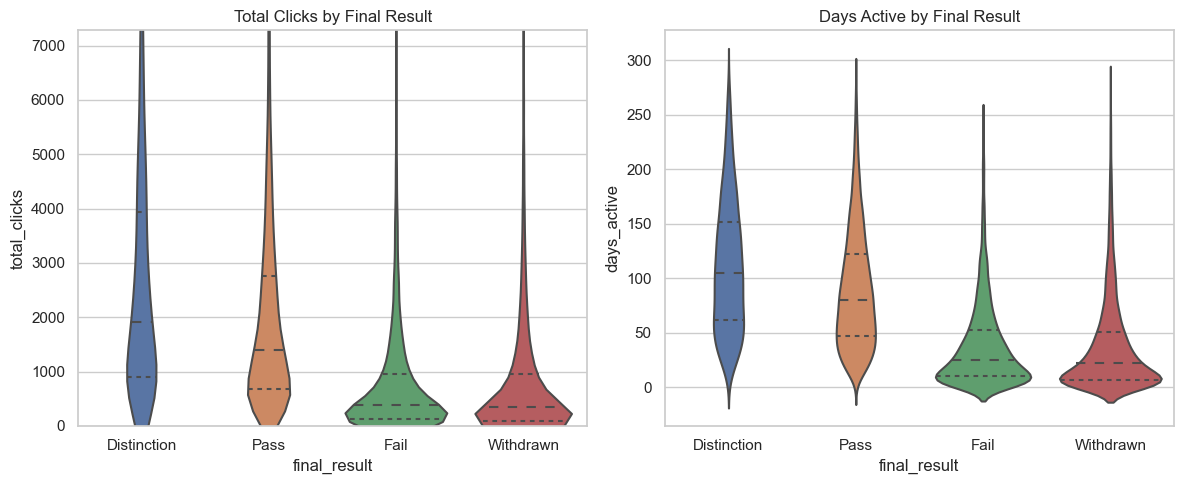

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, column, title in zip(
    axes,
    ["total_clicks", "days_active"],
    ["Total Clicks", "Days Active"]
):
    sns.violinplot(
        data=engagement,
        x="final_result",
        y=column,
        order=result_order,
        inner="quartile",
        ax=ax
    )
    ax.set_title(f"{title} by Final Result")

# Clip extreme click values for readability
axes[0].set_ylim(0, engagement["total_clicks"].quantile(0.98))

plt.tight_layout()
plt.show()

### Total Clicks by Final Result — Violin Plot

### Analysis

- The Distinction distribution is shifted considerably toward higher click counts.
- Pass students also demonstrate relatively high engagement, although lower than Distinction students.
- Fail and Withdrawn students have distributions heavily concentrated at low click counts.
- All groups have long upper tails, indicating that some students are highly active regardless of outcome.
- The dashed lines show that the central tendency is clearly higher for successful students.

### Conclusion

The violin plot reinforces the boxplot finding that **engagement is strongly associated with academic success**. High click activity is much more characteristic of Distinction and Pass students than of Fail or Withdrawn students.

---

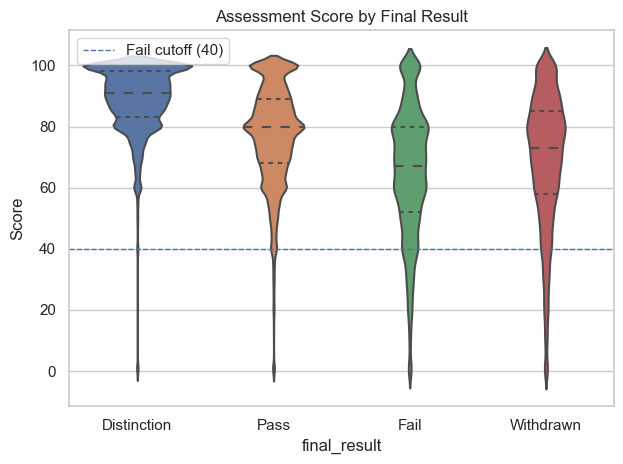

In [33]:
# Join assessment scores with final result
score_by_outcome = student_assessment.merge(
    worst_outcome[["id_student", "final_result"]],
    on="id_student",
    how="left"
)

# Plot
ax = sns.violinplot(
    data=score_by_outcome,
    x="final_result",
    y="score",
    order=result_order,
    inner="quartile"
)

ax.axhline(40, linestyle="--", linewidth=1, label="Fail cutoff (40)")
ax.set_title("Assessment Score by Final Result")
ax.set_ylabel("Score")
ax.legend()

plt.tight_layout()
plt.show()

### Days Active by Final Result — Violin Plot

### Analysis

- Distinction students show the highest and broadest distribution of active days.
- Pass students also tend to remain active for substantially longer.
- Fail and Withdrawn students are concentrated at relatively low numbers of active days.
- There are long tails in all groups, meaning some students remain active for extended periods without necessarily achieving a successful outcome.

### Conclusion

The number of days a student remains actively engaged is an important indicator of outcome. **Low activity is strongly associated with poor outcomes**, particularly Failure and Withdrawal.

---

### 4. Weekly engagement with confidence interval, split by `final_result`

Section 6's weekly average line is a single population-wide curve. This
re-streams `studentVle.csv` computing the same weekly average **per
final_result group**, with a shaded 95% CI band (via bootstrapped
standard error of the mean) so the separation between outcome groups can be
judged against the noise in each week's estimate, not just eyeballed.

In [34]:
outcome_lookup = worst_outcome.set_index("id_student")["final_result"].to_dict()

weekly_data = {
    result: {"sum": {}, "sumsq": {}, "count": {}}
    for result in result_order
}

for chunk in pd.read_csv(
    vle_path,
    chunksize=CHUNK,
    usecols=["id_student", "date", "sum_click"]
):
    chunk["week"] = chunk["date"] // 7
    chunk["final_result"] = chunk["id_student"].map(outcome_lookup)

    chunk = chunk[
        chunk["week"].between(-4, 30)
        & chunk["final_result"].notna()
    ]

    for result, group in chunk.groupby("final_result"):
        weekly = group.groupby("week")["sum_click"]

        for week, values in weekly:
            weekly_data[result]["sum"][week] = (
                weekly_data[result]["sum"].get(week, 0) + values.sum()
            )
            weekly_data[result]["sumsq"][week] = (
                weekly_data[result]["sumsq"].get(week, 0)
                + (values ** 2).sum()
            )
            weekly_data[result]["count"][week] = (
                weekly_data[result]["count"].get(week, 0)
                + values.count()
            )

print("Weekly per-outcome aggregates computed.")


Weekly per-outcome aggregates computed.


In [35]:
# Need id_student -> final_result to split by outcome while streaming
outcome_lookup = worst_outcome.set_index("id_student")["final_result"].to_dict()

weekly_group_sum = {r: {} for r in result_order}
weekly_group_sumsq = {r: {} for r in result_order}
weekly_group_count = {r: {} for r in result_order}

for chunk in pd.read_csv(vle_path, na_values="?", chunksize=CHUNK,
                          usecols=["id_student", "date", "sum_click"]):
    chunk["week"] = (chunk["date"] // 7).astype(int)
    chunk = chunk[(chunk["week"] >= -4) & (chunk["week"] <= 30)]
    chunk["final_result"] = chunk["id_student"].map(outcome_lookup)
    chunk = chunk.dropna(subset=["final_result"])

    for result, g in chunk.groupby("final_result"):
        gw = g.groupby("week")["sum_click"]
        s, sq, c = gw.sum(), (g["sum_click"] ** 2).groupby(g["week"]).sum(), gw.count()
        for wk in s.index:
            weekly_group_sum[result][wk] = weekly_group_sum[result].get(wk, 0) + s[wk]
            weekly_group_sumsq[result][wk] = weekly_group_sumsq[result].get(wk, 0) + sq[wk]
            weekly_group_count[result][wk] = weekly_group_count[result].get(wk, 0) + c[wk]

print("Weekly per-outcome aggregates computed.")

Weekly per-outcome aggregates computed.


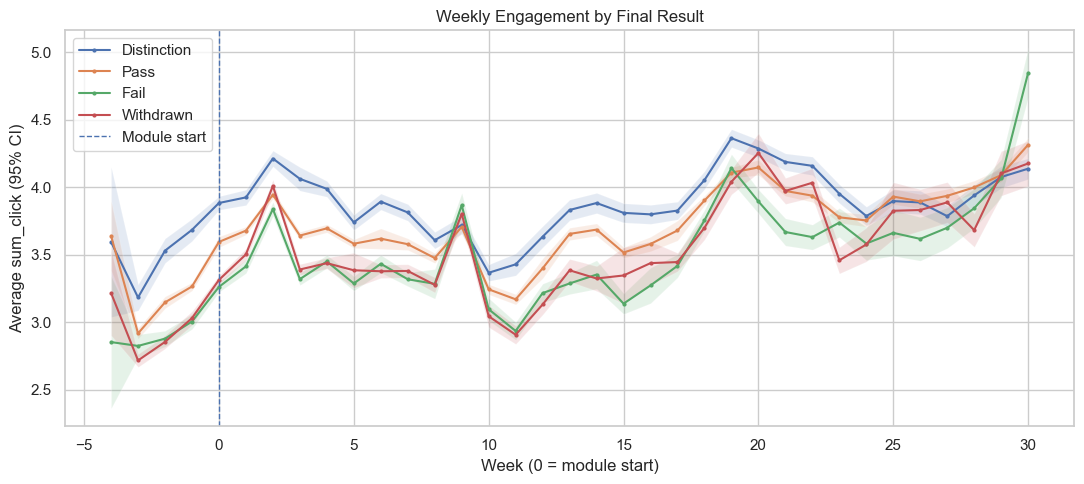

In [36]:
fig, ax = plt.subplots(figsize=(11, 5))

for result in result_order:
    weeks = sorted(weekly_group_sum[result])

    means, lower, upper = [], [], []

    for week in weeks:
        n = weekly_group_count[result][week]
        mean = weekly_group_sum[result][week] / n

        variance = max(
            weekly_group_sumsq[result][week] / n - mean**2,
            0
        )
        se = (variance / n) ** 0.5

        means.append(mean)
        lower.append(mean - 1.96 * se)
        upper.append(mean + 1.96 * se)

    ax.plot(weeks, means, label=result, marker="o", markersize=2)
    ax.fill_between(weeks, lower, upper, alpha=0.15)

ax.axvline(0, linestyle="--", linewidth=1, label="Module start")
ax.set(
    xlabel="Week (0 = module start)",
    ylabel="Average sum_click (95% CI)",
    title="Weekly Engagement by Final Result"
)

ax.legend()
plt.tight_layout()
plt.show()

# 16. Weekly Engagement by Final Result

### Analysis

- **Distinction students consistently have the highest engagement** across much of the module.
- Pass students generally occupy the second-highest position.
- Fail and Withdrawn students usually have lower weekly engagement.
- All groups show similar fluctuations over time, including declines around weeks 10–11 and increases around weeks 18–20.
- Near week 30, engagement rises sharply, especially for the Fail group.

### Conclusion

The graph demonstrates a clear **engagement-performance gradient**: students who ultimately achieve Distinction tend to be more engaged throughout the module. However, late increases in engagement do not necessarily translate into successful outcomes, suggesting that **consistent early engagement may be more important than last-minute activity**.

---

### 5. Cumulative engagement trajectories — percentile bands by outcome

Weekly *snapshots* (Section 4 above) can hide a steady decline that only shows
up when you look at the **running total**. This tracks cumulative clicks
per student per week (10th/50th/90th percentile within each outcome group),
sampling students per group for tractability rather than processing all
~28,785 cumulative trajectories.

In [37]:
SAMPLE_PER_GROUP = 300
rng = np.random.default_rng(42)

# Sample students from each outcome group
sample_ids = {}

for result in result_order:
    ids = [sid for sid, outcome in outcome_lookup.items() if outcome == result]
    sample_ids[result] = set(
        rng.choice(ids, min(SAMPLE_PER_GROUP, len(ids)), replace=False)
    )

all_ids = set().union(*sample_ids.values())

print(f"Sampled {len(all_ids):,} students")

# Collect weekly clicks for sampled students
sampled_weekly = {}

for chunk in pd.read_csv(
    vle_path,
    chunksize=CHUNK,
    usecols=["id_student", "date", "sum_click"]
):
    chunk = chunk[chunk["id_student"].isin(all_ids)]

    if chunk.empty:
        continue

    chunk["week"] = (chunk["date"].clip(lower=0) // 7).astype(int)
    chunk = chunk[chunk["week"] <= 30]

    weekly = chunk.groupby(["id_student", "week"])["sum_click"].sum()

    for (student, week), clicks in weekly.items():
        sampled_weekly.setdefault(student, {})
        sampled_weekly[student][week] = (
            sampled_weekly[student].get(week, 0) + clicks
        )

print(f"Weekly data collected for {len(sampled_weekly):,} students")

Sampled 1,200 students
Weekly data collected for 1,114 students


In [38]:
SAMPLE_PER_GROUP = 300
rng = np.random.default_rng(42)

sample_ids_by_group = {}
for result in result_order:
    ids_in_group = [sid for sid, r in outcome_lookup.items() if r == result]
    chosen = rng.choice(ids_in_group, size=min(SAMPLE_PER_GROUP, len(ids_in_group)), replace=False)
    sample_ids_by_group[result] = set(chosen.tolist())

all_sampled_ids = set().union(*sample_ids_by_group.values())
print(f"Sampled {len(all_sampled_ids):,} students total ({SAMPLE_PER_GROUP} per outcome group, where available)")

sampled_weekly = {}  # id_student -> {week: clicks}
for chunk in pd.read_csv(vle_path, na_values="?", chunksize=CHUNK,
                          usecols=["id_student", "date", "sum_click"]):
    chunk = chunk[chunk["id_student"].isin(all_sampled_ids)]
    if chunk.empty:
        continue
    chunk["week"] = (chunk["date"].clip(lower=0) // 7).astype(int)
    chunk = chunk[chunk["week"] <= 30]
    g = chunk.groupby(["id_student", "week"])["sum_click"].sum()
    for (sid, wk), val in g.items():
        sampled_weekly.setdefault(sid, {})[wk] = sampled_weekly.get(sid, {}).get(wk, 0) + val

print(f"Weekly data collected for {len(sampled_weekly):,} sampled students")

Sampled 1,200 students total (300 per outcome group, where available)
Weekly data collected for 1,114 sampled students


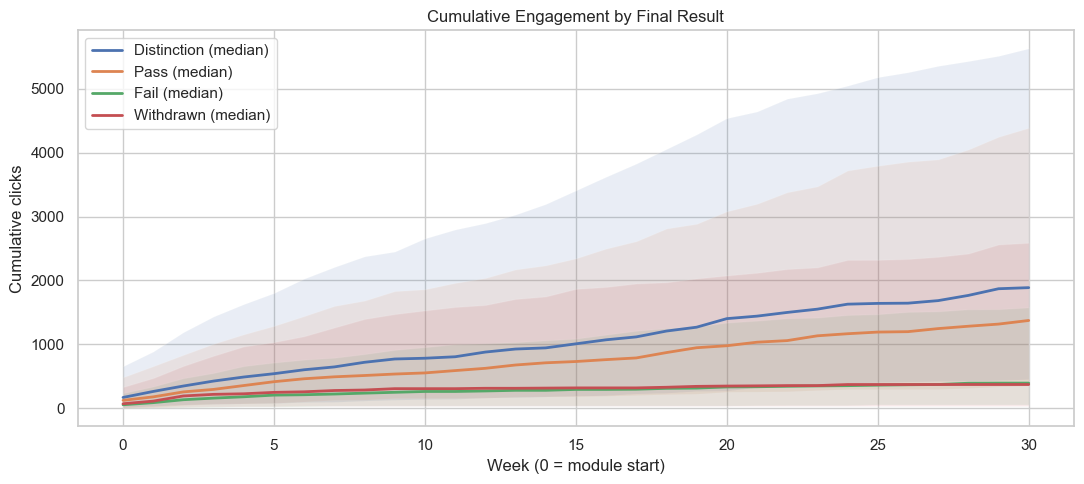

In [39]:
fig, ax = plt.subplots(figsize=(11, 5))

for result in result_order:
    ids = [sid for sid in sample_ids_by_group[result] if sid in sampled_weekly]
    if not ids:
        continue

    # Student × week clicks
    matrix = np.zeros((len(ids), 31))

    for row, sid in enumerate(ids):
        for week, clicks in sampled_weekly[sid].items():
            if 0 <= week <= 30:
                matrix[row, week] = clicks

    # Cumulative clicks
    cumulative = np.cumsum(matrix, axis=1)

    weeks = np.arange(31)
    p10, p50, p90 = np.percentile(cumulative, [10, 50, 90], axis=0)

    # Plot median + 10–90% range
    ax.plot(weeks, p50, label=f"{result} (median)", lw=2)
    ax.fill_between(weeks, p10, p90, alpha=0.12)

ax.set(
    xlabel="Week (0 = module start)",
    ylabel="Cumulative clicks",
    title="Cumulative Engagement by Final Result"
)

ax.legend()
plt.tight_layout()
plt.show()

### Cumulative Engagement by Final Result

### Analysis

- Distinction students accumulate clicks at the fastest rate.
- Pass students show the second-highest cumulative engagement.
- Fail and Withdrawn students accumulate considerably fewer clicks.
- The gap between Distinction and Pass students grows over time.
- The shaded regions indicate substantial variation within each outcome group.

### Conclusion

Cumulative engagement provides strong evidence that **successful students interact with learning materials more consistently over the entire module**. Engagement differences accumulate over time, making cumulative activity potentially useful for early prediction of student outcomes.

---**Reading this:** cumulative curves make the *rate of separation* easier to
see than the weekly-snapshot version — a widening gap between `Withdrawn`'s
median line and `Pass`'s means the two groups are diverging steadily, not just
noisy week to week. The shaded band's width also matters: a wide band within
one outcome group (e.g. `Fail`) means that group is behaviorally diverse, not
one consistent pattern — worth knowing before assuming a single "at-risk
trajectory" describes everyone in it.

### 6. Module-level risk map — heatmap version

Section 3 already showed module risk as a stacked bar. A heatmap of the same
`code_module` × `final_result` table makes it easier to scan for the single
highest-risk module-outcome cell directly, rather than comparing stacked-bar
segment heights.

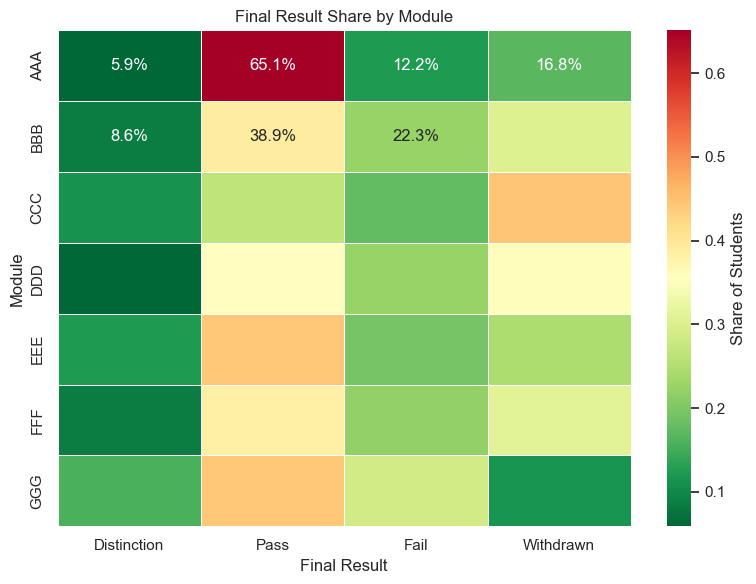

In [40]:
module_result_pct = (
    student_info
    .groupby(["code_module", "final_result"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=result_order, fill_value=0)
)

module_result_pct = (
    module_result_pct
    .div(module_result_pct.sum(axis=1), axis=0)
    .fillna(0)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    module_result_pct,
    annot=True,
    fmt=".1%",
    cmap="RdYlGn_r",
    linewidths=0.5,
    cbar_kws={"label": "Share of Students"}
)

plt.title("Final Result Share by Module")
plt.xlabel("Final Result")
plt.ylabel("Module")
plt.tight_layout()
plt.show()

### Final Result Share by Module — Heatmap

### Analysis

The heatmap highlights strong differences between modules:

- **AAA:** highest Pass share at approximately **65.1%**.
- **BBB:** relatively balanced, with approximately **38.9% Pass**, **22.3% Fail**, and a high Withdrawal share.
- **CCC:** has the highest Withdrawal share, approximately **45%**.
- **DDD:** has relatively similar Pass and Withdrawal proportions.
- **EEE:** has a comparatively high Pass share and relatively low Failure share.
- **FFF:** shows a substantial Withdrawal proportion.
- **GGG:** has the highest Distinction share at approximately **16%**, but also a high Failure share of about **29%**.

### Conclusion

Module-level differences are substantial. **AAA has the strongest overall pass performance, CCC has the greatest withdrawal concern, and GGG produces the highest proportion of distinctions but also a relatively high failure rate.** This suggests that module-specific factors may influence student outcomes.

---

### 7. Assessment submission funnel — submitted → pass/fail, by outcome

Section 7 already noted `studentAssessment` only contains *submitted* work, so
non-submission itself carries risk signal. This makes that funnel explicit:
for each `final_result` group, what share of matched assessment records were
submitted-and-passed vs. submitted-and-failed vs. never appeared in
`studentAssessment` at all (inferred by comparing against how many assessments
existed for their module).

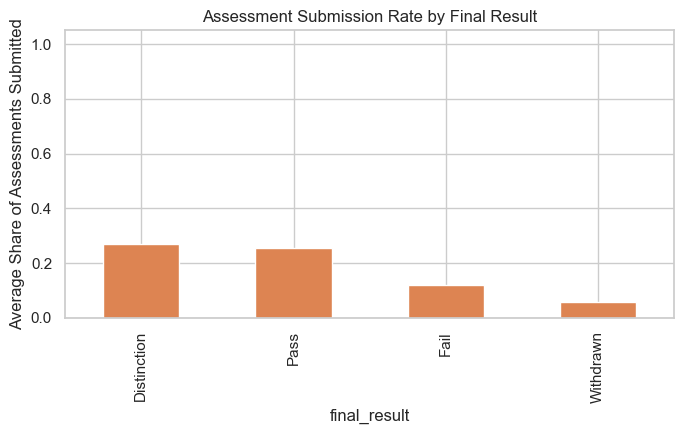

final_result
Distinction    0.269
Pass           0.256
Fail           0.121
Withdrawn      0.057
Name: pct_submitted, dtype: float64


In [41]:
# Assessments expected for each module
assessments_by_module = (
    assessments.groupby("code_module")["id_assessment"]
    .apply(set)
    .to_dict()
)

# Student → module
student_module = (
    student_info.drop_duplicates("id_student")
    .set_index("id_student")["code_module"]
    .to_dict()
)

# Student → submitted assessments
submitted_by_student = (
    student_assessment.groupby("id_student")["id_assessment"]
    .apply(set)
    .to_dict()
)

# Calculate submission rate
funnel_rows = []

for student, result in outcome_lookup.items():
    module = student_module.get(student)
    expected = assessments_by_module.get(module, set())
    submitted = submitted_by_student.get(student, set())

    if expected:
        rate = len(submitted & expected) / len(expected)
        funnel_rows.append({
            "id_student": student,
            "final_result": result,
            "pct_submitted": rate
        })

funnel_df = pd.DataFrame(funnel_rows)

# Average submission rate by outcome
funnel_summary = (
    funnel_df.groupby("final_result")["pct_submitted"]
    .mean()
    .reindex(result_order)
)

# Plot
ax = funnel_summary.plot(
    kind="bar",
    color="#DD8452",
    figsize=(7, 4.5)
)

ax.set(
    ylabel="Average Share of Assessments Submitted",
    title="Assessment Submission Rate by Final Result",
    ylim=(0, 1.05)
)

plt.tight_layout()
plt.show()

print(funnel_summary.round(3))

### Assessment Submission Rate by Final Result

### Analysis

- Distinction students have the highest assessment submission rate, approximately **26–27%**.
- Pass students are close behind at approximately **25%**.
- Fail students have a substantially lower rate of around **12%**.
- Withdrawn students have the lowest submission rate, approximately **5%**.

### Conclusion

Assessment participation is strongly associated with successful completion. **Students who submit more assessments are much more likely to Pass or achieve Distinction**, while low submission rates are particularly associated with Withdrawal.

---

### 8. Correlation heatmap + quick tree-based feature importance

A lightweight numeric feature set — engagement totals plus a couple of
`studentInfo` columns — purely for an EDA-level "what looks predictive" check.
This is **not** the real feature engineering pipeline (that's
`feature_engineering_oulad.ipynb`'s job, with proper leakage guards and a
saved feature matrix); it's a quick correlation + `RandomForestClassifier`
importance check to sanity-check what this EDA has already found visually.

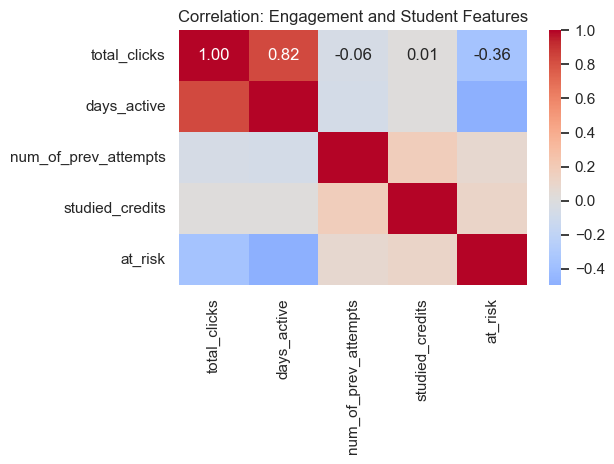

In [42]:
eda_features = (
    engagement
    .merge(
        student_info.drop_duplicates("id_student")[
            ["id_student", "num_of_prev_attempts", "studied_credits"]
        ],
        on="id_student",
        how="left"
    )
    .dropna(subset=["at_risk"])
)

corr_cols = [
    "total_clicks",
    "days_active",
    "num_of_prev_attempts",
    "studied_credits",
    "at_risk"
]

corr_matrix = eda_features[corr_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation: Engagement and Student Features")
plt.tight_layout()
plt.show()

### Correlation: Engagement and Student Features

### Analysis

- `total_clicks` and `days_active` have a strong positive correlation of approximately **0.82**.
- This indicates that students who remain active for more days generally generate more clicks.
- `total_clicks` has a moderate negative relationship with `at_risk`, approximately **-0.36**.
- `days_active` also has a negative relationship with `at_risk`.
- `num_of_prev_attempts` and `studied_credits` have comparatively weak relationships with engagement.

### Conclusion

The strongest relationships are associated with **engagement variables themselves**. Students who spend more days active tend to generate substantially more clicks, while students classified as at risk tend to show lower engagement. This suggests that behavioral engagement is more informative than several background academic variables.

---

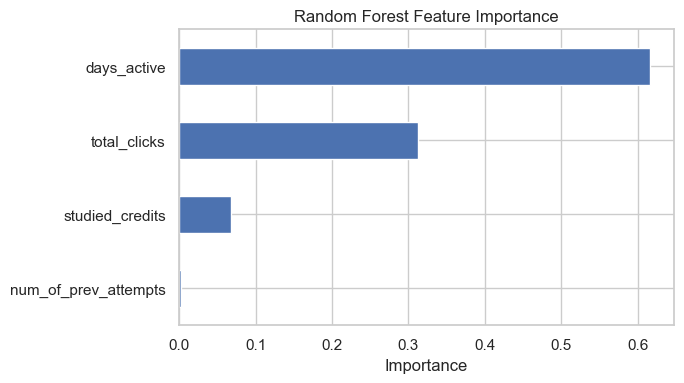

In [43]:
from sklearn.ensemble import RandomForestClassifier

# Features and target
features = [
    "total_clicks",
    "days_active",
    "num_of_prev_attempts",
    "studied_credits"
]

X = eda_features[features].fillna(0)
y = eda_features["at_risk"]

# Train Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

rf.fit(X, y)

# Feature importance
importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values()

# Plot
ax = importance.plot(
    kind="barh",
    figsize=(7, 4)
)

ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Importance")

plt.tight_layout()
plt.show()

### Random Forest Feature Importance

### Analysis

The Random Forest model identifies the following ranking:

1. **`days_active` — approximately 0.61 importance**
2. **`total_clicks` — approximately 0.31**
3. **`studied_credits` — approximately 0.07**
4. **`num_of_prev_attempts` — close to 0**

`days_active` is clearly the dominant feature, contributing roughly twice as much importance as total clicks.

### Conclusion

The model indicates that **student engagement, particularly the number of active days, is the most important predictor among the features shown**. Historical academic variables such as previous attempts appear considerably less influential in comparison.

---

### 9. PCA projection — colored by `at_risk`

Projects the same quick feature set into 2D to visually check how separable
`at_risk` vs. not is in this reduced space — a rough, purely visual proxy for
"how hard is this classification problem," before any real model is trained.

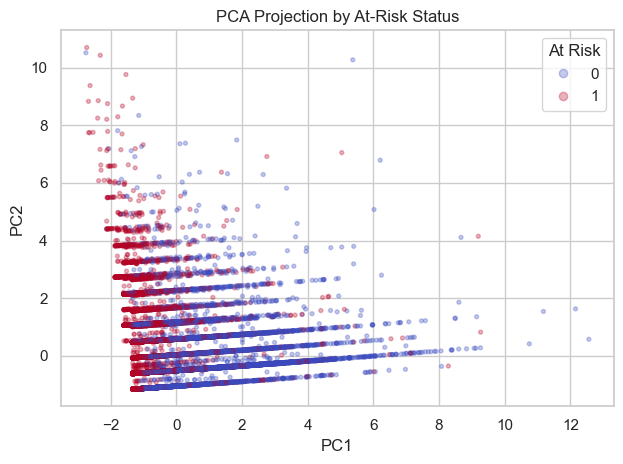

In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Scale features and reduce to 2 dimensions
X_pca = PCA(n_components=2).fit_transform(
    StandardScaler().fit_transform(X)
)

# Plot
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="coolwarm",
    alpha=0.3,
    s=8
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection by At-Risk Status")

plt.legend(
    *scatter.legend_elements(),
    title="At Risk"
)

plt.tight_layout()
plt.show()

### PCA Projection by At-Risk Status

### Analysis

- The PCA projection shows substantial overlap between students classified as **at risk (1)** and **not at risk (0)**.
- Both groups occupy much of the same region of the PCA space.
- At-risk students appear particularly concentrated toward the left side, but they are not completely separated from non-risk students.
- There is no obvious linear boundary separating the two groups.

### Conclusion

The PCA visualization suggests that **at-risk status is not cleanly separable using the available features in a two-dimensional PCA representation**. Although some patterns exist, the substantial overlap indicates that predicting risk likely requires multiple features and potentially nonlinear modeling methods.

**Reading this:** the steepest drop in the curve marks the period of highest
withdrawal risk — if that's concentrated early (first few weeks), interventions
need to trigger fast; if it's spread across the module, there's more sustained
lead time to act on, consistent with Section 8's original finding that most
withdrawals happen well after module start rather than immediately.

### 12. Interactive chart — weekly engagement by module (Plotly)

A hover-and-filter version of Section 6's weekly engagement line, broken out
by `code_module` — useful for spot-checking any one module's pattern without
re-running code, since every earlier chart in this notebook is a static image.

In [47]:
import plotly.express as px

# Student → module
module_lookup = (
    student_info
    .drop_duplicates("id_student")
    .set_index("id_student")["code_module"]
    .to_dict()
)

weekly = {}

# Process VLE data in chunks
for chunk in pd.read_csv(
    vle_path,
    chunksize=CHUNK,
    usecols=["id_student", "date", "sum_click"]
):
    chunk["week"] = chunk["date"] // 7
    chunk["code_module"] = chunk["id_student"].map(module_lookup)

    chunk = chunk[
        chunk["week"].between(-4, 30)
        & chunk["code_module"].notna()
    ]

    grouped = chunk.groupby(["code_module", "week"])["sum_click"]

    for key, values in grouped:
        weekly.setdefault(key, []).extend(values.tolist())

# Create plotting data
plotly_df = pd.DataFrame([
    {
        "code_module": module,
        "week": week,
        "avg_click": np.mean(values)
    }
    for (module, week), values in weekly.items()
])

# Interactive plot
fig = px.line(
    plotly_df,
    x="week",
    y="avg_click",
    color="code_module",
    title="Weekly Engagement by Module",
    labels={
        "week": "Week (0 = Module Start)",
        "avg_click": "Average sum_click"
    }
)

fig.add_vline(x=0, line_dash="dash")
fig.show()

**Reading this:** look for the bottom block (`Withdrawn` students, if sorted
last) fading to dark earlier than the top blocks — that's the individual-level
version of the cumulative trajectory gap from Section 5, and it's the clearest
"can a human see this pattern" check in the whole notebook: if it's obvious by
eye here, a model should be able to learn it too.

## 9. Summary — what this means for `feature_engineering.py` / `build_oulad_static_features()`

- **Target (`at_risk` = Fail or Withdrawn) is ~1-in-3** — imbalanced but workable;
  confirms the plan's imbalance-handling step is needed for OULAD too.
- **`code_module` matters** — Fail/Withdrawn rates vary a lot by module, so it's a
  useful feature or at least a stratification variable for splitting.
- **Engagement (`total_clicks`, `days_active`) tracks outcome directly** —
  Distinction > Pass > Fail > Withdrawn in median engagement. This is OULAD's
  unique contribution the plan calls out (UCI can't see this).
- **`sum_click` is heavily right-skewed** — log-transform candidate.
- **Assessment scores alone understate risk** — non-submission (not just low
  scores) is itself a risk signal, and withdrawn students are under-represented in
  `studentAssessment` simply by not submitting.
- **Withdrawal has lead time** — most `date_unregistration` values are well after
  module start, supporting the Week 2 lead-time / early-warning framing rather than
  only an end-of-module classification.
- **`imd_band`** (and possibly other demographic columns) has missing values worth
  a documented decision before feature engineering, unlike UCI which had none.
- Reminder: this is the OULAD-only half of the pipeline. Per Section 1.3 of the
  plan, none of this is ever joined row-level with the UCI dataset — they unify only
  at the common Risk Service output layer.

**Deep-dive additions (this expanded version):** missingness heatmap + co-occurrence clustermap, type/cardinality summary, violin plots by outcome (clicks, days active, and now `score`), weekly engagement with confidence intervals split by outcome, cumulative engagement trajectories (percentile bands), a module-level risk heatmap, an assessment submission funnel, a quick correlation + RandomForest importance check, a PCA projection, a Kaplan-Meier survival curve for time-to-withdrawal, an interactive Plotly chart, and an individual-student engagement sequence heatmap.